# ACIT4030 Final Project: improving the Assignment 2 NeRF

Asad Mohammad Awais (S374979) and Jaskamal Singh Thiara (S374983)

This notebook holds all the code for our final project report. It defines and trains every run in the report, evaluates them and makes the report figures. Each run has its own settings block in `RUNS` (section 6), and finished runs are saved to Drive.

**Runs**
- `baseline_rerun`: the Assignment 2 model and settings, unchanged (3,000 iterations). Checks that the numbers match Assignment 2 and gives a training time on the same GPU as the new runs.
- `baseline_long`: the Assignment 2 model trained for 20,000 iterations, to separate the gain of Stage 1 from longer training.
- `stage1`: NeRF positional encoding, opacity from the sample spacing, an 8-layer network with a skip connection, stratified sampling, MSE loss, larger ray batches and a decaying learning rate (20,000 iterations).
- `stage2`: Stage 1 with hierarchical sampling, 64 coarse and 128 fine samples per ray with two networks.
- `stage1_256pts`: Stage 1 with 256 evenly spaced samples, the same number of network evaluations per ray as Stage 2.
- `stage3` (poster): scene contraction and inverse-depth sampling for the unbounded room (Barron et al., 2022).
- `stage4` (Stage 4a in the report, poster): one learned appearance code per training image (Martin-Brualla et al., 2021). Test views use the code of the nearest training camera.
- `stage5`: distortion loss (Barron et al., 2022). Lego builds on Stage 2 and poster on Stage 3.
- `kplanes`: K-Planes field (Fridovich-Keil et al., 2023) on the Stage 5 setup for Lego and the Stage 4a setup for poster.
- Analysis runs: seeds 2 and 3 (`<run>_s2`, `<run>_s3`), `stage5_short` and `stage5_weak`, the Lego K-Planes variants, `final` and `kplanes_long` (50,000 iterations on poster) and three runs on Lego at 400 x 400 pixels (dataset `lego400`).

**How to run**
1. Put the course data `acit4030-data.zip` in `MyDrive/ACIT4030/`. Section 0 mounts Drive, installs PyTorch3D and unzips the data. If no PyTorch3D build for the current PyTorch version is cached in Drive, it builds one, which takes about 10 minutes the first time.
2. Choose an L4 GPU with High-RAM. TF32 is switched off in section 0 and must stay off.
3. In section 10, choose `DATASET` and the runs to start (`RUN_MAIN`, `RUN_EXTRA`, `RUN_LATER`). Several copies of the notebook can share one dataset's queue through `WORKER` and `N_WORKERS`.
4. Run all cells. The smoke test in section 9 trains each model for a few hundred iterations in a temporary folder and must finish without errors. Its scores are not results. Each run saves checkpoints and continues from the last one after a disconnect. Finished runs are skipped.
5. With `MAKE_FIGURES = True`, section 12 makes the report figures from the finished runs.

Results go to `MyDrive/ACIT4030/final_project/results/<dataset>/<run>/`. The outputs saved in this copy are from the last session, which only made figures.


## 0. Start of session

In [1]:
import os, sys, glob, json, math, time, shutil, subprocess, importlib, re

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/ACIT4030'
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lpips', 'iopath', 'fvcore'], check=True)
    import torch
    tv = torch.__version__
    # 1) The Assignment 1 install in Drive works only with the PyTorch version it was built for
    old_dir = '/content/drive/MyDrive/Colab_Packages'
    built = open(f'{old_dir}/built_with_torch.txt').read().strip() if os.path.exists(f'{old_dir}/built_with_torch.txt') else None
    if built == tv:
        sys.path.append(old_dir)
        print('Using the PyTorch3D install from Assignment 1')
    else:
        # 2) Otherwise use (or build once) a wheel for this exact PyTorch version, cached in Drive
        wheel_dir = f'{PROJECT_DIR}/wheels/torch-{tv.replace("+", "_")}'
        os.makedirs(wheel_dir, exist_ok=True)
        wheels = glob.glob(f'{wheel_dir}/pytorch3d-*.whl')
        if not wheels:
            print(f'Building PyTorch3D for torch {tv} (one time, about 10 minutes)...')
            subprocess.run('rm -rf /content/p3d_src && git clone -q --depth 1 https://github.com/facebookresearch/pytorch3d.git /content/p3d_src', shell=True, check=True)
            subprocess.run("sed -i 's/-std=c++17/-std=c++20/g' /content/p3d_src/setup.py", shell=True, check=True)
            subprocess.run(f'cd /content/p3d_src && FORCE_CUDA=0 MAX_JOBS=8 {sys.executable} -m pip wheel --no-build-isolation --no-deps . -w "{wheel_dir}"', shell=True, check=True)
            wheels = glob.glob(f'{wheel_dir}/pytorch3d-*.whl')
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', wheels[0]], check=True)
    importlib.invalidate_caches()

    # data: copy the zip to local disk and unzip once per session
    if not os.path.exists('/content/a2data'):
        print('Copying and unzipping data...')
        subprocess.run(f'cp "{PROJECT_DIR}/acit4030-data.zip" /content/a2data.zip && unzip -q /content/a2data.zip -d /content/a2data && rm /content/a2data.zip', shell=True, check=True)
    DATA_ROOT = os.path.dirname(glob.glob('/content/a2data/**/lego', recursive=True)[0])
    RESULTS_ROOT = f'{PROJECT_DIR}/final_project/results'
else:
    DATA_ROOT = os.environ.get('DATA_ROOT', './data')
    RESULTS_ROOT = os.environ.get('RESULTS_ROOT', './results')
os.makedirs(RESULTS_ROOT, exist_ok=True)

import torch
import pytorch3d
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'
# TF32 must stay OFF: with it on, the L4 trained both models to only about 13 dB on Lego
# (baseline 13.67 dB vs 22.16 dB on the T4). PyTorch3D's camera and ray maths needs full float32 precision.
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
print('torch', torch.__version__, '| pytorch3d', pytorch3d.__version__, '| device:', GPU_NAME)
print('data:', DATA_ROOT, sorted(os.listdir(DATA_ROOT)))
print('results:', RESULTS_ROOT)

Mounted at /content/drive
Copying and unzipping data...
torch 2.11.0+cu130 | pytorch3d 0.7.9 | device: NVIDIA L4
data: /content/a2data/data ['lego', 'load_nerf_data.py', 'poster']
results: /content/drive/MyDrive/ACIT4030/final_project/results


## 1. Imports

In [2]:
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from pytorch3d.renderer import (
    FoVPerspectiveCameras, NDCMultinomialRaysampler, MonteCarloRaysampler,
    EmissionAbsorptionRaymarcher, ImplicitRenderer, RayBundle, ray_bundle_to_ray_points,
)
# The pure-PyTorch version of PyTorch3D's sample_pdf: same algorithm, but it does not need PyTorch3D's
# compiled CUDA kernels, which only exist for the GPU type the package was built on (L4, not A100).
from pytorch3d.renderer.implicit.sample_pdf import sample_pdf_python as sample_pdf

## 2. Data (corrected loader from Assignment 2, unchanged)

In [3]:
GL_TO_P3D = torch.diag(torch.tensor([-1.0, 1.0, -1.0]))

def c2w_to_pytorch3d(c2w):
    R = c2w[:3, :3] @ GL_TO_P3D
    T = -R.T @ c2w[:3, 3]
    return R, T


def load_nerf_data_fixed(data_dir, split='train', device='cpu', znear=0.01, zfar=100.0,
                         resize_to=None, image_subdir=None, frame_ids=None):
    path = os.path.join(data_dir, f'transforms_{split}.json')
    if not os.path.exists(path):
        path = os.path.join(data_dir, 'transforms.json')
    meta = json.load(open(path))
    frames = meta['frames']
    if frame_ids is not None:
        frames = [frames[i] for i in frame_ids]

    def img_path(fr):
        rel = fr['file_path'].replace('./', '')
        if image_subdir is not None:
            rel = os.path.join(image_subdir, os.path.basename(rel))
        p = os.path.join(data_dir, rel)
        return p if p.lower().endswith(('.png', '.jpg', '.jpeg')) else p + '.png'

    w0, h0 = Image.open(img_path(frames[0])).size
    full_w, full_h = meta.get('w', w0), meta.get('h', h0)
    H, W = resize_to if resize_to else (h0, w0)
    if 'fl_x' in meta:
        fx, fy = meta['fl_x'] * W / full_w, meta['fl_y'] * H / full_h
    else:
        fx = 0.5 * full_w / math.tan(0.5 * meta['camera_angle_x']) * W / full_w
        fy = fx
    fov = math.degrees(2 * math.atan(0.5 * W / fx)) if W <= H else math.degrees(2 * math.atan(0.5 * H / fy))

    images, sils, Rs, Ts = [], [], [], []
    for fr in frames:
        im = torch.from_numpy(np.asarray(Image.open(img_path(fr)), dtype=np.float32) / 255.0)
        if im.shape[-1] == 4:
            rgb, sil = im[..., :3], im[..., 3]
        else:
            rgb, sil = im[..., :3], torch.ones(im.shape[:2])
        if (H, W) != tuple(rgb.shape[:2]):
            rgb = F.interpolate(rgb.permute(2, 0, 1)[None], size=(H, W), mode='area')[0].permute(1, 2, 0)
            sil = F.interpolate(sil[None, None], size=(H, W), mode='area')[0, 0]
        images.append(rgb); sils.append(sil)
        R, T = c2w_to_pytorch3d(torch.tensor(fr['transform_matrix'], dtype=torch.float32))
        Rs.append(R); Ts.append(T)
    cams = FoVPerspectiveCameras(R=torch.stack(Rs), T=torch.stack(Ts), fov=fov, degrees=True,
                                 znear=znear, zfar=zfar, device=device)
    print(f'{os.path.basename(data_dir)}/{split}: {len(frames)} views, {W}x{H}, fov={fov:.2f} deg')
    return torch.stack(images).to(device), torch.stack(sils).to(device), cams


# Same protocol as Assignment 2
DATASETS = {
    'lego': dict(data_dir=os.path.join(DATA_ROOT, 'lego'), resize_to=(200, 200), image_subdir=None,
                 min_depth=2.0, max_depth=6.0, white_bkgd=True, test_every=None, show_views=[1, 14, 18]),
    'poster': dict(data_dir=os.path.join(DATA_ROOT, 'poster'), resize_to=None, image_subdir='images_4',
                   min_depth=0.5, max_depth=12.0, white_bkgd=False, test_every=8, show_views=[2, 10, 12]),
}
# Analysis only: lego at 400x400, to test whether more training pixels help the grid model
DATASETS['lego400'] = dict(DATASETS['lego'], resize_to=(400, 400))

_DATA_CACHE = {}
def load_dataset(name):
    if name in _DATA_CACHE:
        return _DATA_CACHE[name]
    cfg = DATASETS[name]
    kw = dict(device=device, resize_to=cfg['resize_to'], image_subdir=cfg['image_subdir'])
    if cfg['test_every'] is None:
        tr = load_nerf_data_fixed(cfg['data_dir'], 'train', **kw)
        te = load_nerf_data_fixed(cfg['data_dir'], 'test', **kw)
    else:
        n = len(json.load(open(os.path.join(cfg['data_dir'], 'transforms.json')))['frames'])
        test_ids = list(range(0, n, cfg['test_every']))
        train_ids = [i for i in range(n) if i not in test_ids]
        tr = load_nerf_data_fixed(cfg['data_dir'], 'train', frame_ids=train_ids, **kw)
        te = load_nerf_data_fixed(cfg['data_dir'], 'test', frame_ids=test_ids, **kw)
    if cfg['white_bkgd']:  # straight alpha: composite onto white
        tr = (tr[0] * tr[1][..., None] + (1 - tr[1][..., None]), tr[1], tr[2])
        te = (te[0] * te[1][..., None] + (1 - te[1][..., None]), te[1], te[2])
    # Stage 4a: each test view borrows the appearance code of the training view with the nearest camera
    d = torch.cdist(te[2].get_camera_center(), tr[2].get_camera_center())
    _DATA_CACHE[name] = dict(train=tr, test=te, test_code_idx=d.argmin(dim=1).tolist())
    return _DATA_CACHE[name]

## 3. Metrics (unchanged from Assignment 2)

In [4]:
def psnr(pred, gt):
    return float(-10.0 * torch.log10(F.mse_loss(pred, gt)))

def ssim(pred, gt, data_range=1.0):
    x, y = pred.permute(2, 0, 1)[:, None], gt.permute(2, 0, 1)[:, None]
    g = torch.exp(-(torch.arange(11, device=pred.device) - 5) ** 2 / (2 * 1.5 ** 2)); g = g / g.sum()
    w = (g[:, None] @ g[None, :])[None, None]
    C1, C2 = (0.01 * data_range) ** 2, (0.03 * data_range) ** 2
    mx, my = F.conv2d(x, w), F.conv2d(y, w)
    sxx = F.conv2d(x * x, w) - mx ** 2; syy = F.conv2d(y * y, w) - my ** 2; sxy = F.conv2d(x * y, w) - mx * my
    return float((((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx ** 2 + my ** 2 + C1) * (sxx + syy + C2))).mean())

try:
    import lpips
    _lpips_net = lpips.LPIPS(net='alex', verbose=False).to(device).eval()
except Exception as e:
    print('LPIPS unavailable:', e)
    _lpips_net = None

@torch.no_grad()
def lpips_score(pred, gt):
    if _lpips_net is None:
        return float('nan')
    to = lambda im: im.permute(2, 0, 1)[None] * 2 - 1
    return float(_lpips_net(to(pred), to(gt)))

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 209MB/s]


## 4. Radiance fields

`BookNeRF` is the Assignment 2 baseline, unchanged. `NeRFField` is the Stage 1 model following
Mildenhall et al. (2020): positional encoding with frequencies 2^k * pi (10 for position, 4 for
direction, raw input included), 8 layers of 256 units with the encoded input concatenated again at
layer 5, density from the trunk and a 128-unit colour branch that sees the viewing direction.
Opacity is 1 - exp(-sigma * delta), where delta is the world distance between samples.

In [5]:
class HarmonicEmbedding(nn.Module):
    def __init__(self, n_harmonic_functions=60, omega0=0.1):
        super().__init__()
        self.register_buffer('frequencies', omega0 * (2.0 ** torch.arange(n_harmonic_functions)))
    def forward(self, x):
        embed = (x[..., None] * self.frequencies).view(*x.shape[:-1], -1)
        return torch.cat((embed.sin(), embed.cos()), dim=-1)


class BookNeRF(nn.Module):
    """Chapter 6 baseline (Assignment 2), unchanged."""
    def __init__(self, n_harmonic_functions=60, n_hidden_neurons=256):
        super().__init__()
        self.harmonic_embedding = HarmonicEmbedding(n_harmonic_functions)
        embedding_dim = n_harmonic_functions * 2 * 3
        self.mlp = nn.Sequential(
            nn.Linear(embedding_dim, n_hidden_neurons), nn.Softplus(beta=10.0),
            nn.Linear(n_hidden_neurons, n_hidden_neurons), nn.Softplus(beta=10.0))
        self.color_layer = nn.Sequential(
            nn.Linear(n_hidden_neurons + embedding_dim, n_hidden_neurons), nn.Softplus(beta=10.0),
            nn.Linear(n_hidden_neurons, 3), nn.Sigmoid())
        self.density_layer = nn.Sequential(nn.Linear(n_hidden_neurons, 1), nn.Softplus(beta=10.0))
        self.density_layer[0].bias.data[0] = -1.5

    def forward(self, ray_bundle, **kwargs):
        features = self.mlp(self.harmonic_embedding(ray_bundle_to_ray_points(ray_bundle)))
        densities = 1 - (-self.density_layer(features)).exp()
        spatial = features.shape[:-1]
        d = self.harmonic_embedding(F.normalize(ray_bundle.directions, dim=-1))
        d = d[..., None, :].expand(*spatial, d.shape[-1])
        colors = self.color_layer(torch.cat((features, d), dim=-1))
        return densities, colors


class PositionalEncoding(nn.Module):
    """gamma(x) = [x, sin(2^k pi x), cos(2^k pi x)] for k = 0..L-1 (Mildenhall et al., 2020)."""
    def __init__(self, n_freqs, include_input=True):
        super().__init__()
        self.include_input = include_input
        self.register_buffer('freqs', math.pi * 2.0 ** torch.arange(n_freqs))
        self.out_dim = 3 * (int(include_input) + 2 * n_freqs)
    def forward(self, x):
        e = (x[..., None] * self.freqs).flatten(-2)
        out = [e.sin(), e.cos()]
        return torch.cat(([x] if self.include_input else []) + out, dim=-1)


def contract_points(x):
    """Scene contraction (Barron et al., 2022): unchanged inside the unit sphere, everything outside
    is mapped into the shell between radius 1 and 2, so the whole unbounded scene fits in a ball."""
    n = x.norm(dim=-1, keepdim=True).clamp_min(1e-6)
    return torch.where(n <= 1, x, (2 - 1 / n) * x / n)


class NeRFField(nn.Module):
    """Stage 1 radiance field (original NeRF architecture)."""
    def __init__(self, pe_pos=10, pe_dir=4, width=256, depth=8, skip=4, contract=False, app_dim=0):
        super().__init__()
        self.pe_x, self.pe_d, self.skip = PositionalEncoding(pe_pos), PositionalEncoding(pe_dir), skip
        # Stage 3: points are shifted and scaled so the camera path lies in the unit sphere, then contracted
        self.contract = contract
        self.register_buffer('scene_center', torch.zeros(3))
        self.register_buffer('scene_scale', torch.ones(()))
        dims = [self.pe_x.out_dim] + [width + (self.pe_x.out_dim if i == skip else 0) for i in range(1, depth)]
        self.layers = nn.ModuleList([nn.Linear(d, width) for d in dims])
        self.sigma_head = nn.Linear(width, 1)
        self.feature = nn.Linear(width, width)
        self.app_dim = app_dim   # Stage 4a: per-image appearance code fed to the colour branch only
        self.rgb_hidden = nn.Linear(width + self.pe_d.out_dim + app_dim, width // 2)
        self.rgb_out = nn.Linear(width // 2, 3)

    def query(self, points, dirs, codes=None):
        e = self.pe_x(points)
        h = e
        for i, layer in enumerate(self.layers):
            if i == self.skip:
                h = torch.cat([h, e], dim=-1)
            h = F.relu(layer(h))
        sigma = F.softplus(self.sigma_head(h)[..., 0] - 1.0)   # shifted softplus for stable early training
        colour_in = [self.feature(h), self.pe_d(dirs)]
        if self.app_dim:
            colour_in.append(codes[..., None, :].expand(*points.shape[:-1], self.app_dim))
        c = F.relu(self.rgb_hidden(torch.cat(colour_in, dim=-1)))
        return sigma, torch.sigmoid(self.rgb_out(c))

    def forward(self, ray_bundle, **kwargs):
        points = ray_bundle_to_ray_points(ray_bundle)                      # (..., P, 3)
        dirs = F.normalize(ray_bundle.directions, dim=-1)[..., None, :].expand_as(points)
        if self.contract:
            points = contract_points((points - self.scene_center) * self.scene_scale)
        sigma, rgb = self.query(points, dirs, kwargs.get('codes'))
        # world-space distance between samples (our ray directions are not unit length)
        dl = ray_bundle.lengths[..., 1:] - ray_bundle.lengths[..., :-1]
        dl = torch.cat([dl, dl[..., -1:]], dim=-1) * ray_bundle.directions.norm(dim=-1, keepdim=True)
        alpha = 1.0 - torch.exp(-sigma * dl)
        return alpha[..., None], rgb


class KPlanesField(nn.Module):
    """Stretch goal: K-Planes radiance field (Fridovich-Keil et al., 2023), static 3D version.
    Three learnable 2D feature planes (xy, xz, yz) per resolution. A point's feature is the product of
    its three bilinearly sampled plane features, concatenated over resolutions, and a small MLP decodes
    density and colour. Same interface as NeRFField, including contraction and appearance codes."""
    def __init__(self, resolutions=(64, 128, 256, 512), feat=32, hidden=64, pe_dir=4, contract=False,
                 app_dim=0, bound=1.5):
        super().__init__()
        self.contract, self.app_dim = contract, app_dim
        self.bound = 2.0 if contract else bound       # contracted space lies in [-2, 2]
        self.register_buffer('scene_center', torch.zeros(3))
        self.register_buffer('scene_scale', torch.ones(()))
        self.planes = nn.ParameterList()
        for r in resolutions:
            for _ in range(3):
                self.planes.append(nn.Parameter(torch.empty(1, feat, r, r).uniform_(0.1, 0.5)))
        self.n_res, self.pe_d = len(resolutions), PositionalEncoding(pe_dir)
        self.sigma_net = nn.Sequential(nn.Linear(feat * self.n_res, hidden), nn.ReLU(), nn.Linear(hidden, 1 + 15))
        self.rgb_net = nn.Sequential(nn.Linear(15 + self.pe_d.out_dim + app_dim, hidden), nn.ReLU(),
                                     nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 3))

    def features(self, x):
        x = (x / self.bound).clamp(-1, 1).reshape(1, -1, 1, 3)
        pairs = (x[..., [0, 1]], x[..., [0, 2]], x[..., [1, 2]])
        out = []
        for s in range(self.n_res):
            f = 1.0
            for p in range(3):
                f = f * F.grid_sample(self.planes[3 * s + p], pairs[p], mode='bilinear', align_corners=True)
            out.append(f[0, :, :, 0].T)                     # (N, feat)
        return torch.cat(out, dim=-1)

    def tv_loss(self):
        """Total variation on every plane: keeps the learned features spatially smooth."""
        return sum(((p[..., 1:, :] - p[..., :-1, :]) ** 2).mean() + ((p[..., :, 1:] - p[..., :, :-1]) ** 2).mean()
                   for p in self.planes)

    def forward(self, ray_bundle, **kwargs):
        points = ray_bundle_to_ray_points(ray_bundle)
        shape = points.shape[:-1]
        dirs = F.normalize(ray_bundle.directions, dim=-1)[..., None, :].expand_as(points)
        if self.contract:
            points = contract_points((points - self.scene_center) * self.scene_scale)
        h = self.sigma_net(self.features(points.reshape(-1, 3))).view(*shape, 16)
        sigma = F.softplus(h[..., 0] - 1.0)
        if not self.contract:   # bounded scene: no density outside the grid (clamped points would repeat the border)
            sigma = sigma * (points.abs() <= self.bound).all(dim=-1)
        colour_in = [h[..., 1:], self.pe_d(dirs)]
        codes = kwargs.get('codes')
        if self.app_dim:
            colour_in.append(codes[..., None, :].expand(*shape, self.app_dim))
        rgb = torch.sigmoid(self.rgb_net(torch.cat(colour_in, dim=-1)))
        dl = ray_bundle.lengths[..., 1:] - ray_bundle.lengths[..., :-1]
        dl = torch.cat([dl, dl[..., -1:]], dim=-1) * ray_bundle.directions.norm(dim=-1, keepdim=True)
        return (1.0 - torch.exp(-sigma * dl))[..., None], rgb


class HierarchicalNeRF(nn.Module):
    """Stage 2: coarse and fine NeRFField networks (Mildenhall et al., 2020).
    The coarse pass's rendering weights define a distribution along each ray, and n_fine extra
    depths are drawn from it with PyTorch3D's sample_pdf. The fine network renders all samples."""
    def __init__(self, cfg):
        super().__init__()
        args = (cfg['pe_pos'], cfg['pe_dir'], cfg['width'], cfg['depth'], cfg['skip'], cfg.get('contract', False),
                cfg.get('app_dim', 0))
        if cfg.get('field') == 'kplanes':   # small low-resolution coarse grid, full fine grid
            kw = dict(contract=cfg.get('contract', False), app_dim=cfg.get('app_dim', 0))
            self.coarse = (KPlanesField(resolutions=cfg['kp_res'], feat=cfg['kp_feat'], **kw) if cfg.get('kp_full_coarse')
                           else KPlanesField(resolutions=(64, 128), feat=8, **kw))
            self.fine = KPlanesField(resolutions=cfg['kp_res'], feat=cfg['kp_feat'], **kw)
            self.n_fine = cfg['n_fine']
        else:
            self.coarse, self.fine, self.n_fine = NeRFField(*args), NeRFField(*args), cfg['n_fine']


def build_model(cfg):
    if cfg.get('hierarchical'):
        return HierarchicalNeRF(cfg)
    if cfg['model'] == 'book':
        return BookNeRF()
    if cfg['model'] == 'nerf':
        return NeRFField(cfg['pe_pos'], cfg['pe_dir'], cfg['width'], cfg['depth'], cfg['skip'], cfg.get('contract', False), cfg.get('app_dim', 0))
    raise ValueError(cfg['model'])

## 5. Rendering helpers

In [6]:
def huber(x, y, scaling=0.1):
    diff_sq = (x - y) ** 2
    return ((1 + diff_sq / (scaling ** 2)).clamp(1e-4).sqrt() - 1) * float(scaling)

def ndc_extent(H, W):
    return (W / H, 1.0) if W >= H else (1.0, H / W)

def sample_images_at_mc_locs(target_images, xys, H, W):
    ba, dim = target_images.shape[0], target_images.shape[-1]
    spatial = xys.shape[1:-1]
    sx, sy = ndc_extent(H, W)
    grid = -xys.view(ba, -1, 1, 2) / torch.tensor([sx, sy], device=xys.device)
    out = F.grid_sample(target_images.permute(0, 3, 1, 2), grid, align_corners=False)
    return out.permute(0, 2, 3, 1).view(ba, *spatial, dim)

def composite(rendered, white_bkgd):
    rgb, alpha = rendered.split([3, 1], dim=-1)
    if white_bkgd:
        rgb = rgb + (1.0 - alpha)
    return rgb, alpha[..., 0]

def subset_cameras(cams, idx):
    return FoVPerspectiveCameras(R=cams.R[idx], T=cams.T[idx], znear=cams.znear[idx], zfar=cams.zfar[idx],
                                 aspect_ratio=cams.aspect_ratio[idx], fov=cams.fov[idx], device=cams.device)

def make_renderers(cfg, dcfg, H, W, frac=1.0):
    dcfg = dict(dcfg, min_depth=cfg.get('min_depth', dcfg['min_depth']), max_depth=cfg.get('max_depth', dcfg['max_depth']))
    sx, sy = ndc_extent(H, W)
    sx, sy = sx * frac, sy * frac
    raymarcher = EmissionAbsorptionRaymarcher()
    mc = ImplicitRenderer(raysampler=MonteCarloRaysampler(
        min_x=-sx, max_x=sx, min_y=-sy, max_y=sy, n_rays_per_image=cfg['rays_per_image'],
        n_pts_per_ray=cfg['n_pts'], min_depth=dcfg['min_depth'], max_depth=dcfg['max_depth'],
        stratified_sampling=cfg['stratified']), raymarcher=raymarcher).to(device)
    grid = ImplicitRenderer(raysampler=NDCMultinomialRaysampler(
        image_height=H, image_width=W, n_pts_per_ray=cfg['n_pts'],
        min_depth=dcfg['min_depth'], max_depth=dcfg['max_depth'], stratified_sampling=False),
        raymarcher=raymarcher).to(device)
    return mc, grid

RAYMARCHER = EmissionAbsorptionRaymarcher()

def ray_weights(alpha):
    """w_i = alpha_i * prod_{j<i} (1 - alpha_j): how much each sample contributes to the pixel."""
    a = alpha[..., 0]
    T = torch.cumprod(torch.cat([torch.ones_like(a[..., :1]), 1.0 - a[..., :-1] + 1e-10], dim=-1), dim=-1)
    return a * T

def to_s(model, t):
    """Normalised ray distance in [0, 1]: linear in depth, or linear in 1/depth for inverse-depth sampling."""
    near, far = model.near, model.far
    if getattr(model, 'sampling', 'linear') == 'disparity':
        return (1 / t - 1 / near) / (1 / far - 1 / near)
    return (t - near) / (far - near)

def disparity_lengths(model, like, train):
    """Stage 3: sample depths evenly in 1/depth between near and far (Barron et al., 2022), so nearby
    content gets dense samples and the distant room gets few. Jittered within each interval when training."""
    P = like.shape[-1]
    u = torch.arange(P, device=like.device, dtype=like.dtype)
    u = (u.expand_as(like) + (torch.rand_like(like) if train else 0.5)) / P
    return 1.0 / ((1 - u) / model.near + u / model.far)

def render_rays(model, ray_bundle, white_bkgd, train, codes=None):
    """Returns {'main': (rgb, alpha), 'w': weights, 't': lengths} and, for the hierarchical model, 'coarse'."""
    if getattr(model, 'sampling', 'linear') == 'disparity':
        ray_bundle = RayBundle(origins=ray_bundle.origins, directions=ray_bundle.directions,
                               lengths=disparity_lengths(model, ray_bundle.lengths, train), xys=ray_bundle.xys)
    if not isinstance(model, HierarchicalNeRF):
        a, c = model(ray_bundle, codes=codes)
        return dict(main=composite(RAYMARCHER(rays_densities=a, rays_features=c), white_bkgd),
                    w=ray_weights(a), t=ray_bundle.lengths)
    a_c, c_c = model.coarse(ray_bundle, codes=codes)
    w = ray_weights(a_c).detach()
    l = ray_bundle.lengths
    mid = 0.5 * (l[..., 1:] + l[..., :-1])
    l_fine = sample_pdf(mid.contiguous(), w[..., 1:-1].contiguous(), model.n_fine, det=not train).detach()
    l_all, _ = torch.sort(torch.cat([l, l_fine], dim=-1), dim=-1)
    fine_bundle = RayBundle(origins=ray_bundle.origins, directions=ray_bundle.directions, lengths=l_all, xys=ray_bundle.xys)
    a_f, c_f = model.fine(fine_bundle, codes=codes)
    return dict(main=composite(RAYMARCHER(rays_densities=a_f, rays_features=c_f), white_bkgd),
                coarse=composite(RAYMARCHER(rays_densities=a_c, rays_features=c_c), white_bkgd),
                w=ray_weights(a_f), t=l_all)

def distortion_loss(model, w, t):
    """Stage 5: Mip-NeRF 360 distortion loss on one pass's weights w and sample depths t (sorted).
    Sum_ij w_i w_j |s_i - s_j| + 1/3 Sum_i w_i^2 ds_i, computed in O(P) with cumulative sums."""
    s = to_s(model, t)
    ds = torch.cat([s[..., 1:] - s[..., :-1], (s[..., -1:] - s[..., -2:-1])], dim=-1)
    W = torch.cumsum(w, dim=-1) - w           # sum of weights before sample i
    M = torch.cumsum(w * s, dim=-1) - w * s   # sum of w_j * s_j before sample i
    inter = 2 * (w * (s * W - M)).sum(-1)
    intra = (w ** 2 * ds).sum(-1) / 3
    return (inter + intra).mean()

@torch.no_grad()
def render_full(model, renderer_grid, cam, white_bkgd, chunk=8192, code_idx=None, return_depth=False):
    """Renders one full image, sending the rays through the network in chunks.
    code_idx: which training image's appearance code to use (Stage 4a only)."""
    rb = renderer_grid.raysampler(cameras=cam)
    shape, P = rb.origins.shape[:-1], rb.lengths.shape[-1]
    o, d, l = rb.origins.reshape(-1, 3), rb.directions.reshape(-1, 3), rb.lengths.reshape(-1, P)
    code = None
    if hasattr(model, 'appearance') and code_idx is not None:
        code = model.appearance(torch.tensor([code_idx], device=o.device))[0]
    rgbs, alphas, depths = [], [], []
    for i in range(0, o.shape[0], chunk):
        n = min(chunk, o.shape[0] - i)
        out = render_rays(model, RayBundle(origins=o[i:i + chunk], directions=d[i:i + chunk],
                                           lengths=l[i:i + chunk], xys=None), white_bkgd, train=False,
                          codes=None if code is None else code.expand(n, -1))
        rgbs.append(out['main'][0]); alphas.append(out['main'][1])
        if return_depth:   # expected depth along the ray, sum_i w_i t_i / sum_i w_i
            depths.append((out['w'] * out['t']).sum(-1) / out['w'].sum(-1).clamp_min(1e-6))
    rgb = torch.cat(rgbs).view(*shape, 3)[0]
    alpha = torch.cat(alphas).view(*shape)[0]
    if return_depth:
        return rgb.clamp(0, 1), alpha, torch.cat(depths).view(*shape)[0]
    return rgb.clamp(0, 1), alpha

## 6. Run settings

One settings block per run. Each new stage adds its runs here.

In [7]:
COMMON = dict(seed=1, log_every=100, ckpt_every=1000, precrop_iters=0, precrop_frac=0.5)

BOOK = dict(model='book', lr=1e-3, lr_schedule='book', batch_images=6, rays_per_image=750, n_pts=128,
            loss='huber', stratified=False, sil_weight={'lego': 1.0, 'poster': 1.0})

RUNS = {
    'baseline_rerun': dict(BOOK, n_iter=3000,
                           note='Assignment 2 model and settings, unchanged'),
    'baseline_long': dict(BOOK, n_iter=20000,
                          note='Assignment 2 model trained as long as the new runs'),
    'stage1': dict(model='nerf', n_iter=20000, lr=5e-4, lr_final=5e-5, lr_schedule='exp',
                   batch_images=8, rays_per_image=512, n_pts=128, loss='mse', stratified=True,
                   sil_weight={'lego': 1.0, 'poster': 0.0},
                   pe_pos=10, pe_dir=4, width=256, depth=8, skip=4, eval_every=1000,
                   precrop_iters=0, precrop_frac=0.5,
                   note='NeRF encoding, sigma*delta opacity, 8x256 network with skip, stratified sampling, MSE'),
}
# Stage 2: hierarchical sampling, 64 coarse + 128 fine samples (192 per ray for the fine network)
RUNS['stage2'] = dict(RUNS['stage1'], hierarchical=True, n_pts=64, n_fine=128,
                      note='Stage 1 + hierarchical sampling (64 coarse + 128 fine samples, two networks)')
# Control for Stage 2: Stage 1 with the same number of network evaluations per ray (64 + 192 = 256)
RUNS['stage1_256pts'] = dict(RUNS['stage1'], n_pts=256,
                             note='Stage 1 with 256 evenly spaced samples: same compute per ray as Stage 2')

# Which run the later stages build on. We use 'stage2', which was not worse than the 256-sample control.
STAGE_BASE = 'stage2'

# Stage 3 (poster only): scene contraction and inverse-depth sampling, far bound pushed out to 100
RUNS['stage3'] = dict(RUNS[STAGE_BASE], contract=True, sampling='disparity', max_depth=100.0,
                      note=f'{STAGE_BASE} + scene contraction and inverse-depth sampling (far = 100)')
# Stage 5: distortion loss (weight 0.01 as in Mip-NeRF 360). Lego builds on the base, poster on Stage 3.
# Stage 4a (poster): per-image appearance codes (Martin-Brualla et al., 2021) on top of Stage 3.
# Test views use the code of the training view with the nearest camera.
RUNS['stage4'] = dict(RUNS['stage3'], app_dim=32,
                      note='stage3 + 32-d appearance code per training image (test: nearest training camera)')
# Final poster model: Stage 4a trained longer (it was still improving at 20,000 iterations). Run on the A100.
RUNS['final'] = {'poster': dict(RUNS['stage4'], n_iter=50000, eval_every=5000,
                                note='stage4 trained for 50,000 iterations (final poster model)')}
# Stretch goal: K-Planes field instead of the MLP, on each dataset's best setup. Grids need a higher learning rate.
KP = dict(field='kplanes', kp_res=(64, 128, 256, 512), kp_feat=32, tv_weight=1e-4, lr=1e-2, lr_final=1e-4)
RUNS['stage5'] = {
    'lego': dict(RUNS[STAGE_BASE], dist_weight=0.01, note=f'{STAGE_BASE} + distortion loss (0.01)'),
    'poster': dict(RUNS['stage3'], dist_weight=0.01, note='stage3 + distortion loss (0.01)'),
}
RUNS['kplanes'] = {
    'lego': dict(RUNS['stage5']['lego'], **KP, note='K-Planes field (64-512, 32 features) on the Stage 5 setup'),
    'poster': dict(RUNS['stage4'], **KP, note='K-Planes field (64-512, 32 features) on the Stage 4a setup'),
}
# Lego K-Planes analysis: grid resolution, smoothing and coarse-grid size
RUNS['kplanes_256'] = {'lego': dict(RUNS['kplanes']['lego'], kp_res=(64, 128, 256), note='K-Planes with grids up to 256')}
RUNS['kplanes_128'] = {'lego': dict(RUNS['kplanes']['lego'], kp_res=(32, 64, 128), note='K-Planes with grids up to 128')}
RUNS['kplanes_256_tv'] = {'lego': dict(RUNS['kplanes']['lego'], kp_res=(64, 128, 256), tv_weight=1e-3,
                                       note='K-Planes with grids up to 256 and 10x stronger TV')}
RUNS['kplanes_fullcoarse'] = {'lego': dict(RUNS['kplanes']['lego'], kp_full_coarse=True,
                                           note='K-Planes with a full-size coarse grid')}
for r in ['stage5', 'kplanes', 'kplanes_256']:
    RUNS[r]['lego400'] = dict(RUNS[r]['lego'], sil_weight=1.0)
RUNS['kplanes_long'] = {'poster': dict(RUNS['kplanes']['poster'], n_iter=50000, eval_every=5000,
                                       note='K-Planes for 50,000 iterations (same budget as final)')}
# Extra analysis runs
RUNS['stage5_weak'] = {'poster': dict(RUNS['stage5']['poster'], dist_weight=0.001,
                                      note='stage5 with a 10x weaker distortion loss (0.001)')}
RUNS['stage5_short'] = {'lego': dict(RUNS['stage5']['lego'], n_iter=5000,
                                     note='stage5 stopped at 5,000 iterations (near the held-out peak)')}

def make_config(dataset, run, **overrides):
    seed = None
    m = re.fullmatch(r'(.+)_s(\d+)', run)
    if m and m.group(1) in RUNS:              # 'stage2_s2' = run 'stage2' with seed 2
        run_base, seed = m.group(1), int(m.group(2))
    else:
        run_base = run
    spec = RUNS[run_base]
    spec = spec[dataset] if dataset in spec else spec          # some runs differ per dataset
    cfg = dict(COMMON, **spec)
    cfg.update(overrides)
    cfg['sil_weight'] = cfg['sil_weight'][dataset] if isinstance(cfg['sil_weight'], dict) else cfg['sil_weight']
    cfg.setdefault('eval_every', max(100, cfg['n_iter'] // 10))
    if seed is not None:
        cfg['seed'] = seed
    cfg.update(dataset=dataset, run=run)
    return cfg

def lr_at(cfg, it):
    if cfg['lr_schedule'] == 'exp':
        return cfg['lr'] * (cfg['lr_final'] / cfg['lr']) ** (it / cfg['n_iter'])
    return cfg['lr'] if it < round(cfg['n_iter'] * 0.75) else cfg['lr'] * 0.1   # book: 10x drop at 75%

## 7. Training with checkpoints

Saves a checkpoint to Drive every `ckpt_every` iterations and continues from the last one if the
run is started again. Training time excludes the monitoring renders.

In [8]:
def save_json(obj, path):
    tmp = path + '.tmp'
    json.dump(obj, open(tmp, 'w'), indent=2)
    os.replace(tmp, path)

def train(cfg, data, run_dir):
    dcfg = DATASETS[cfg['dataset']]
    images, sils, cams = data['train']
    t_images, _, t_cams = data['test']
    N, H, W, _ = images.shape
    torch.manual_seed(cfg['seed']); np.random.seed(cfg['seed'])
    model = build_model(cfg).to(device)
    # how depths are sampled along each ray (used by render_rays and the distortion loss)
    model.sampling = cfg.get('sampling', 'linear')
    model.near, model.far = cfg.get('min_depth', dcfg['min_depth']), cfg.get('max_depth', dcfg['max_depth'])
    if cfg.get('contract'):
        centers = cams.get_camera_center()
        c = centers.mean(0); r = (centers - c).norm(dim=-1).max()
        for m in model.modules():
            if isinstance(m, (NeRFField, KPlanesField)):
                m.scene_center.copy_(c); m.scene_scale.fill_(float(1.0 / r))
        print(f'Scene normalisation: centre {c.cpu().numpy().round(2)}, camera radius {float(r):.2f}')
    if cfg.get('app_dim'):
        model.appearance = nn.Embedding(N, cfg['app_dim']).to(device)   # one learnable code per training image
        nn.init.normal_(model.appearance.weight, std=0.01)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr_at(cfg, 0))
    renderer_mc, renderer_grid = make_renderers(cfg, dcfg, H, W)
    # warm-up on the image centre: keeps the deep network from collapsing to empty space early on
    renderer_crop = make_renderers(cfg, dcfg, H, W, frac=cfg['precrop_frac'])[0] if cfg['precrop_iters'] > 0 else renderer_mc
    hist = dict(iter=[], loss=[], color=[], sil=[], eval_iter=[], eval_psnr=[], train_time_s=0.0)
    start = 0
    ckpt_path = os.path.join(run_dir, 'ckpt.pt')
    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        # checkpoints from before Stage 3 have no scene-normalisation buffers. Their defaults (centre 0,
        # scale 1) are exactly what those models used, so only those keys may be missing.
        missing, unexpected = model.load_state_dict(ck['model'], strict=False)
        assert not unexpected and all(k.endswith(('scene_center', 'scene_scale')) for k in missing), (missing, unexpected)
        if cfg['lr_schedule'] == 'book' and ck['iter'] >= round(cfg['n_iter'] * 0.75):
            optimizer = torch.optim.Adam(model.parameters(), lr=lr_at(cfg, ck['iter']))
        optimizer.load_state_dict(ck['optimizer'])
        start, hist = ck['iter'], ck['hist']
        torch.manual_seed(cfg['seed'] + start)
        print(f'Resuming {cfg["dataset"]}/{cfg["run"]} from iteration {start}')
    monitor = list(range(0, len(t_cams), max(1, len(t_cams) // 3)))[:3]
    t_last = time.time()

    def checkpoint(it):
        hist['train_time_s'] += time.time() - t_last
        tmp = ckpt_path + '.tmp'
        torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(), iter=it, hist=hist), tmp)
        os.replace(tmp, ckpt_path)

    model.train()
    for it in tqdm(range(start, cfg['n_iter']), initial=start, total=cfg['n_iter'], desc=f'{cfg["dataset"]}/{cfg["run"]}'):
        if cfg['lr_schedule'] == 'book' and it == round(cfg['n_iter'] * 0.75):
            optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'] * 0.1)   # as in the book
        for g in optimizer.param_groups:
            g['lr'] = lr_at(cfg, it)
        idx = torch.randperm(N)[:cfg['batch_images']]
        renderer = renderer_crop if it < cfg['precrop_iters'] else renderer_mc
        rays = renderer.raysampler(cameras=subset_cameras(cams, idx))
        codes = None
        if hasattr(model, 'appearance'):
            codes = model.appearance(idx.to(device))[:, None, :].expand(-1, rays.origins.shape[1], -1)
        out = render_rays(model, rays, dcfg['white_bkgd'], train=True, codes=codes)
        rgb, alpha = out['main']
        gt_rgb = sample_images_at_mc_locs(images[idx], rays.xys, H, W)
        crit = (lambda a, b: huber(a, b).abs().mean()) if cfg['loss'] == 'huber' else F.mse_loss
        passes = [out['main']] + ([out['coarse']] if 'coarse' in out else [])   # NeRF trains both passes
        loss_c = sum(crit(p[0], gt_rgb) for p in passes)
        loss_s = torch.zeros((), device=device)
        if cfg['sil_weight'] > 0:
            gt_sil = sample_images_at_mc_locs(sils[idx, ..., None], rays.xys, H, W)[..., 0]
            loss_s = sum(crit(p[1], gt_sil) for p in passes)
        loss = loss_c + cfg['sil_weight'] * loss_s
        if cfg.get('dist_weight', 0) > 0:
            loss = loss + cfg['dist_weight'] * distortion_loss(model, out['w'], out['t'])
        if cfg.get('tv_weight', 0) > 0:
            loss = loss + cfg['tv_weight'] * sum(m.tv_loss() for m in model.modules() if isinstance(m, KPlanesField))
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % cfg['log_every'] == 0:
            hist['iter'].append(it); hist['loss'].append(loss.item())
            hist['color'].append(loss_c.item()); hist['sil'].append(loss_s.item())
        if (it + 1) % cfg['eval_every'] == 0 or it == cfg['n_iter'] - 1:
            hist['train_time_s'] += time.time() - t_last
            model.eval()
            p = np.mean([psnr(render_full(model, renderer_grid, subset_cameras(t_cams, [i]), dcfg['white_bkgd'],
                                          code_idx=data['test_code_idx'][i])[0], t_images[i])
                         for i in monitor])
            model.train()
            hist['eval_iter'].append(it + 1); hist['eval_psnr'].append(float(p))
            tqdm.write(f'[{cfg["dataset"]}/{cfg["run"]}] it {it + 1}: loss {loss.item():.5f} held-out PSNR {p:.2f} dB, mean opacity {alpha.mean().item():.2f}')
            if cfg['dataset'] == 'lego' and it + 1 >= 3000 and p < 17:
                tqdm.write('WARNING: PSNR still below 17 dB. Training has probably collapsed. Stop the run and send the output.')
            t_last = time.time()
        if (it + 1) % cfg['ckpt_every'] == 0 or it == cfg['n_iter'] - 1:
            checkpoint(it + 1)
            t_last = time.time()
    model.eval()
    return model, renderer_grid, hist

## 8. Evaluation and figures

Same metrics and test views as Assignment 2. Every test render is saved as a PNG so later notebooks
can build side-by-side comparisons between stages without re-rendering.

In [9]:
@torch.no_grad()
def evaluate(cfg, model, renderer_grid, data, run_dir):
    dcfg = DATASETS[cfg['dataset']]
    t_images, _, t_cams = data['test']
    os.makedirs(os.path.join(run_dir, 'renders'), exist_ok=True)
    gt_dir = os.path.join(RESULTS_ROOT, cfg['dataset'], '_ground_truth')
    os.makedirs(gt_dir, exist_ok=True)
    rows, preds = [], []
    t0 = time.time()
    for i in tqdm(range(len(t_cams)), desc='evaluate'):
        pred, _ = render_full(model, renderer_grid, subset_cameras(t_cams, [i]), dcfg['white_bkgd'],
                              code_idx=data['test_code_idx'][i])
        gt = t_images[i]
        rows.append(dict(view=i, psnr=psnr(pred, gt), ssim=ssim(pred, gt), lpips=lpips_score(pred, gt)))
        preds.append(pred.cpu())
        Image.fromarray((pred.cpu().numpy() * 255).round().astype(np.uint8)).save(os.path.join(run_dir, 'renders', f'view_{i:03d}.png'))
        gp = os.path.join(gt_dir, f'view_{i:03d}.png')
        if not os.path.exists(gp):
            Image.fromarray((gt.cpu().numpy() * 255).round().astype(np.uint8)).save(gp)
    summary = {k: float(np.nanmean([r[k] for r in rows])) for k in ('psnr', 'ssim', 'lpips')}
    for k in ('psnr', 'ssim', 'lpips'):
        summary[k + '_min'] = float(np.nanmin([r[k] for r in rows])); summary[k + '_max'] = float(np.nanmax([r[k] for r in rows]))
    summary.update(n_test_views=len(rows), render_seconds_per_view=(time.time() - t0) / len(rows))
    save_json(dict(summary=summary, per_view=rows), os.path.join(run_dir, 'metrics.json'))
    print(f'[{cfg["dataset"]}/{cfg["run"]}] PSNR {summary["psnr"]:.2f} dB | SSIM {summary["ssim"]:.4f} | LPIPS {summary["lpips"]:.4f}')
    return summary, rows, torch.stack(preds)

def save_figures(cfg, hist, rows, preds, data, run_dir, show=True):
    t_images = data['test'][0].cpu()
    views = [v for v in DATASETS[cfg['dataset']]['show_views'] if v < len(rows)] or list(range(min(3, len(rows))))
    hw = t_images.shape[1] / t_images.shape[2]
    fig, ax = plt.subplots(len(views), 3, figsize=(9, 3 * len(views) * hw), squeeze=False)
    for r, i in enumerate(views):
        err = (preds[i] - t_images[i]).abs().mean(-1)
        for c, (im, title) in enumerate([(t_images[i], 'ground truth'), (preds[i], f'render ({rows[i]["psnr"]:.1f} dB)'), (err, 'abs. error')]):
            ax[r, c].imshow(im.numpy(), cmap='inferno' if c == 2 else None, vmin=0, vmax=1 if c < 2 else 0.5)
            ax[r, c].set_title(f'view {i}: {title}', fontsize=9); ax[r, c].axis('off')
    fig.suptitle(f'{cfg["dataset"]} / {cfg["run"]}'); fig.tight_layout()
    fig.savefig(os.path.join(run_dir, 'qualitative.png'), dpi=150)
    plt.show() if show else None; plt.close(fig)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
    ax[0].plot(hist['iter'], hist['color']); ax[0].set_title('colour loss'); ax[0].set_yscale('log')
    ax[1].plot(hist['iter'], hist['sil']); ax[1].set_title('silhouette loss')
    ax[2].plot(hist['eval_iter'], hist['eval_psnr'], 'o-'); ax[2].set_title('held-out PSNR (3 views)'); ax[2].set_ylabel('dB')
    for a in ax: a.set_xlabel('iteration'); a.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(os.path.join(run_dir, 'training_curves.png'), dpi=150)
    plt.show() if show else None; plt.close(fig)

## 9. Run one experiment, and a smoke test

In [10]:
def run_experiment(dataset, run, results_root=None, show=True, **overrides):
    results_root = results_root or RESULTS_ROOT
    run_dir = os.path.join(results_root, dataset, run)
    os.makedirs(run_dir, exist_ok=True)
    if os.path.exists(os.path.join(run_dir, 'summary.json')):
        print(f'{dataset}/{run} already finished, skipping')
        return json.load(open(os.path.join(run_dir, 'summary.json')))
    cfg = make_config(dataset, run, **overrides)
    save_json(cfg, os.path.join(run_dir, 'config.json'))
    data = load_dataset(dataset)
    model, renderer_grid, hist = train(cfg, data, run_dir)
    save_json(hist, os.path.join(run_dir, 'history.json'))
    summary, rows, preds = evaluate(cfg, model, renderer_grid, data, run_dir)
    summary.update(train_time_min=hist['train_time_s'] / 60, gpu=GPU_NAME, n_iter=cfg['n_iter'],
                   n_params=sum(p.numel() for p in model.parameters()), note=cfg.get('note', ''))
    save_figures(cfg, hist, rows, preds, data, run_dir, show=show)
    save_json(summary, os.path.join(run_dir, 'summary.json'))
    return summary

In [11]:
# Smoke test: a few hundred iterations of each model on the chosen dataset, in a temporary folder.
# Takes a few minutes. It must finish without errors before the queue below is started.
SMOKE_DATASET = 'lego'
smoke_root = os.path.join(RESULTS_ROOT, f'_smoke_{int(time.time())}')   # own folder, so two notebooks never clash
for r in ['baseline_rerun', 'stage4', 'kplanes']:
    run_experiment(SMOKE_DATASET, r, results_root=smoke_root, show=False, n_iter=200, eval_every=100, ckpt_every=100)
shutil.rmtree(smoke_root, ignore_errors=True)
print('Smoke test passed')

lego/train: 50 views, 200x200, fov=39.60 deg
lego/test: 20 views, 200x200, fov=39.60 deg


lego/baseline_rerun:   0%|          | 0/200 [00:00<?, ?it/s]

[lego/baseline_rerun] it 100: loss 0.07344 held-out PSNR 17.54 dB, mean opacity 0.21
[lego/baseline_rerun] it 200: loss 0.05817 held-out PSNR 18.56 dB, mean opacity 0.23


evaluate:   0%|          | 0/20 [00:00<?, ?it/s]

[lego/baseline_rerun] PSNR 18.12 dB | SSIM 0.7137 | LPIPS 0.4003
Scene normalisation: centre [ 0.11 -0.38  2.4 ], camera radius 4.62


lego/stage4:   0%|          | 0/200 [00:00<?, ?it/s]

... (3 outputs left out)

lego/kplanes:   0%|          | 0/200 [00:00<?, ?it/s]

[lego/kplanes] it 100: loss 0.26211 held-out PSNR 15.03 dB, mean opacity 0.19
[lego/kplanes] it 200: loss 0.26660 held-out PSNR 15.10 dB, mean opacity 0.19


evaluate:   0%|          | 0/20 [00:00<?, ?it/s]

[lego/kplanes] PSNR 15.52 dB | SSIM 0.6723 | LPIPS 0.5355
Smoke test passed


## 10. The queue

Runs one after another and skips finished runs. Safe to start again after a disconnect.
For poster, run a copy of this notebook with `DATASET = 'poster'`.

In [12]:
DATASET = 'lego'
WORKER, N_WORKERS = 0, 2     # several notebooks per dataset: give each copy its own WORKER (0, 1, ...)
MAKE_FIGURES = True          # all runs are finished, so this session only makes the report figures

# The main chain. Everything here is finished except poster 'final', which runs on the A100 notebook.
MAIN = ['baseline_rerun', 'stage1', 'baseline_long', 'stage2', 'stage1_256pts']
MAIN += {'lego': ['stage5'], 'poster': ['stage3', 'stage5', 'stage4', 'final']}.get(DATASET, [])
# Extra runs for the final report: K-Planes, two more seeds for the close comparisons, two analysis runs.
EXTRA = {'lego': ['kplanes', 'stage2_s2', 'stage1_256pts_s2', 'stage5_s2', 'stage5_short',
                  'stage2_s3', 'stage1_256pts_s3', 'stage5_s3'],
         'poster': ['kplanes', 'stage3_s2', 'stage4_s2', 'stage5_s2', 'stage5_weak',
                    'stage3_s3', 'stage4_s3', 'stage5_s3']}.get(DATASET, [])
# Runs added last: Lego K-Planes variants, poster K-Planes seeds and 50,000 iterations, Lego at 400 x 400.
LATER = {'lego': ['kplanes_256', 'kplanes_128', 'kplanes_256_tv', 'kplanes_fullcoarse'],
         'poster': ['kplanes_s2', 'kplanes_s3', 'kplanes_long'],
         'lego400': ['stage5', 'kplanes', 'kplanes_256']}.get(DATASET, [])
RUN_MAIN = False             # leave False: the main chain is done, and 'final' must not start twice
RUN_EXTRA = False            # the extra runs are finished too
RUN_LATER = False            # and so are these

split = lambda runs: [r for i, r in enumerate(runs) if i % N_WORKERS == WORKER]
queue = (MAIN if RUN_MAIN else []) + (split(EXTRA) if RUN_EXTRA else []) + (split(LATER) if RUN_LATER else [])
print(f'{DATASET}, worker {WORKER} of {N_WORKERS}: {queue}')
for run in queue:
    run_experiment(DATASET, run)

lego, worker 0 of 2: []


## 11. Results table

Collects every finished run. Run this cell any time, also while other runs are still going.

In [13]:
def results_table(save=True):
    A2 = {'lego': (22.16, 0.841, 0.169, 23.0), 'poster': (19.29, 0.641, 0.798, 25.0)}
    lines = ['| Dataset | Run | PSNR (dB) | SSIM | LPIPS | Iterations | Train (min) | GPU |',
             '| --- | --- | --- | --- | --- | --- | --- | --- |']
    rows = []
    for ds in ['lego', 'poster', 'lego400']:
        p, s, l, t = A2.get(ds, (None,) * 4)
        if p is not None:
            lines.append(f'| {ds} | A2 baseline (reported) | {p:.2f} | {s:.3f} | {l:.3f} | 3000 | {t:.1f} | Tesla T4 |')
        for f in sorted(glob.glob(os.path.join(RESULTS_ROOT, ds, '*', 'summary.json'))):
            run = os.path.basename(os.path.dirname(f))
            m = json.load(open(f))
            rows.append(dict(dataset=ds, run=run, **{k: m.get(k) for k in ('psnr', 'ssim', 'lpips', 'n_iter', 'train_time_min', 'gpu')}))
            lines.append(f'| {ds} | {run} | {m["psnr"]:.2f} | {m["ssim"]:.3f} | {m["lpips"]:.3f} | {m["n_iter"]} | {m["train_time_min"]:.1f} | {m["gpu"]} |')
    table = '\n'.join(lines)
    # runs repeated with several seeds: mean and standard deviation ('stage2', 'stage2_s2', 'stage2_s3' -> 'stage2')
    groups = {}
    for r in rows:
        m = re.fullmatch(r'(.+)_s(\d+)', r['run'])
        base = m.group(1) if m and m.group(1) in RUNS else r['run']
        groups.setdefault((r['dataset'], base), []).append(r)
    agg = ['| Dataset | Run | Seeds | PSNR (dB) | SSIM | LPIPS |', '| --- | --- | --- | --- | --- | --- |']
    for (ds, base), g in groups.items():
        if len(g) > 1:
            f = lambda k, d: f'{np.mean([x[k] for x in g]):.{d}f} ± {np.std([x[k] for x in g], ddof=1):.{d}f}'
            agg.append(f'| {ds} | {base} | {len(g)} | {f("psnr", 2)} | {f("ssim", 3)} | {f("lpips", 3)} |')
    if len(agg) > 2:
        table += '\n\nMean ± standard deviation over seeds\n\n' + '\n'.join(agg)
    if save:
        open(os.path.join(RESULTS_ROOT, 'results_table.md'), 'w').write(table + '\n')
    print(table)
    return rows

_ = results_table()

| Dataset | Run | PSNR (dB) | SSIM | LPIPS | Iterations | Train (min) | GPU |
| --- | --- | --- | --- | --- | --- | --- | --- |
| lego | A2 baseline (reported) | 22.16 | 0.841 | 0.169 | 3000 | 23.0 | Tesla T4 |
| lego | baseline_long | 22.52 | 0.899 | 0.094 | 20000 | 71.0 | NVIDIA L4 |
| lego | baseline_rerun | 22.21 | 0.841 | 0.169 | 3000 | 10.7 | NVIDIA L4 |
| lego | kplanes | 21.97 | 0.907 | 0.094 | 20000 | 84.5 | NVIDIA L4 |
| lego | kplanes_128 | 22.21 | 0.904 | 0.096 | 20000 | 24.3 | NVIDIA A100-SXM4-80GB |
| lego | kplanes_256 | 22.63 | 0.907 | 0.091 | 20000 | 23.9 | NVIDIA A100-SXM4-80GB |
| lego | kplanes_256_tv | 22.61 | 0.909 | 0.093 | 20000 | 23.6 | NVIDIA A100-SXM4-80GB |
| lego | kplanes_fullcoarse | 22.17 | 0.906 | 0.095 | 20000 | 37.6 | NVIDIA A100-SXM4-40GB |
| lego | stage1 | 23.19 | 0.896 | 0.118 | 20000 | 126.2 | NVIDIA L4 |
| lego | stage1_256pts | 23.23 | 0.903 | 0.105 | 20000 | 245.8 | NVIDIA L4 |
| lego | stage1_256pts_s2 | 23.49 | 0.903 | 0.102 | 20000 | 245.1 

## 12. Report figures

Uses the saved renders and checkpoints, so nothing is retrained. Everything is saved to
`results/figures/`. Runs that are missing are skipped, so this works for whichever dataset is finished.

In [14]:
FIG_DIR = os.path.join(RESULTS_ROOT, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
LABELS = {'baseline_long': 'Baseline (20k)', 'stage1': 'Stage 1', 'stage2': 'Stage 2', 'stage3': 'Stage 3',
          'stage4': 'Stage 4a', 'stage5': 'Stage 5', 'final': 'Final (50k)', 'stage1_256pts': 'Stage 1, 256 pts',
          'kplanes': 'K-Planes', 'stage5_short': 'Stage 5, 5k', 'stage5_weak': 'Stage 5, weak',
          'kplanes_256': 'K-Planes 256', 'kplanes_128': 'K-Planes 128', 'kplanes_256_tv': 'K-Planes 256, TV',
          'kplanes_fullcoarse': 'K-Planes, full coarse', 'kplanes_long': 'K-Planes (50k)'}
FIG_RUNS = {'lego': ['baseline_long', 'stage1', 'stage2', 'stage5', 'kplanes_256'],
            'poster': ['baseline_long', 'stage1', 'stage2', 'stage3', 'stage4', 'final', 'kplanes']}

def finished(ds, run):
    return os.path.exists(os.path.join(RESULTS_ROOT, ds, run, 'summary.json'))

def load_trained(ds, run):
    """Rebuilds a finished model from its saved settings and checkpoint."""
    run_dir = os.path.join(RESULTS_ROOT, ds, run)
    cfg = json.load(open(os.path.join(run_dir, 'config.json')))
    model, renderer_grid, _ = train(cfg, load_dataset(ds), run_dir)   # loads the checkpoint, trains 0 iterations
    return model.eval(), renderer_grid

def stage_comparison(ds, runs=None, name='stage_comparison'):
    """Ground truth next to every stage for the same test views (the Assignment 2 views)."""
    runs = [r for r in (runs or FIG_RUNS[ds]) if finished(ds, r)]
    n_views = len(load_dataset(ds)['test'][0])
    views = [v for v in DATASETS[ds]['show_views'] if v < n_views] or [0]
    gt_dir = os.path.join(RESULTS_ROOT, ds, '_ground_truth')
    per_view = {r: json.load(open(os.path.join(RESULTS_ROOT, ds, r, 'metrics.json')))['per_view'] for r in runs}
    cols = 1 + len(runs)
    h, w = np.asarray(Image.open(os.path.join(gt_dir, 'view_000.png'))).shape[:2]
    fig, ax = plt.subplots(len(views), cols, figsize=(2.2 * cols, 2.2 * len(views) * h / w), squeeze=False)
    for r_i, v in enumerate(views):
        ax[r_i, 0].imshow(Image.open(os.path.join(gt_dir, f'view_{v:03d}.png'))); ax[r_i, 0].set_title(f'view {v}: ground truth', fontsize=8)
        for c_i, run in enumerate(runs, start=1):
            ax[r_i, c_i].imshow(Image.open(os.path.join(RESULTS_ROOT, ds, run, 'renders', f'view_{v:03d}.png')))
            ax[r_i, c_i].set_title(f'{LABELS[run]} ({per_view[run][v]["psnr"]:.1f} dB)', fontsize=8)
    for a in ax.ravel(): a.axis('off')
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, f'{ds}_{name}.png'), dpi=200); plt.show(); plt.close(fig)

def curve_comparison(ds):
    """Held-out PSNR during training for every run of one dataset."""
    fig, ax = plt.subplots(figsize=(6.5, 3.5))
    for run in ['baseline_long'] + [r for r in FIG_RUNS[ds] if r != 'baseline_long'] + ['stage1_256pts']:
        if finished(ds, run):
            h = json.load(open(os.path.join(RESULTS_ROOT, ds, run, 'history.json')))
            ax.plot(h['eval_iter'], h['eval_psnr'], marker='o', ms=3, label=LABELS[run])
    ax.set_xlabel('iteration'); ax.set_ylabel('held-out PSNR (dB, 3 views)'); ax.grid(alpha=.3); ax.legend(fontsize=8)
    ax.set_title(f'{ds}: held-out PSNR during training')
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, f'{ds}_training_curves.png'), dpi=200); plt.show(); plt.close(fig)

def depth_comparison(ds, runs, view):
    """Colour and inverse depth for one test view: floaters and missing geometry show up clearly in depth."""
    runs = [r for r in runs if finished(ds, r)]
    data = load_dataset(ds); t_cams = data['test'][2]
    fig, ax = plt.subplots(2, len(runs), figsize=(3 * len(runs), 6 * data['test'][0].shape[1] / data['test'][0].shape[2]), squeeze=False)
    for c, run in enumerate(runs):
        model, grid = load_trained(ds, run)
        rgb, alpha, depth = render_full(model, grid, subset_cameras(t_cams, [view]), DATASETS[ds]['white_bkgd'],
                                        code_idx=data['test_code_idx'][view], return_depth=True)
        disp = (1 / depth.clamp_min(1e-3)) * (alpha > 0.5)
        lo, hi = torch.quantile(disp[alpha > 0.5], torch.tensor([0.02, 0.98], device=disp.device)) if (alpha > 0.5).any() else (0, 1)
        ax[0, c].imshow(rgb.cpu().numpy()); ax[0, c].set_title(LABELS[run], fontsize=9)
        ax[1, c].imshow(((disp - lo) / (hi - lo + 1e-6)).clamp(0, 1).cpu().numpy(), cmap='turbo'); ax[1, c].set_title('inverse depth', fontsize=9)
        del model; torch.cuda.empty_cache() if torch.cuda.is_available() else None
    for a in ax.ravel(): a.axis('off')
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, f'{ds}_depth_view{view}.png'), dpi=200); plt.show(); plt.close(fig)

@torch.no_grad()
def make_video(ds, run, n_frames=90):
    """Lego: 360 degree orbit at 30 degrees elevation. Poster: along the capture path."""
    from pytorch3d.renderer import look_at_view_transform
    import imageio
    if not finished(ds, run):
        return
    model, grid = load_trained(ds, run)
    data = load_dataset(ds); cams = data['train'][2]
    if ds == 'lego':
        az = torch.linspace(0, 2 * math.pi, n_frames + 1)[:-1]; el, r = math.radians(30), 4.031
        eye = torch.stack([r * math.cos(el) * az.cos(), r * math.cos(el) * az.sin(), torch.full_like(az, r * math.sin(el))], -1)
        R, T = look_at_view_transform(eye=eye, at=((0, 0, 0),), up=((0, 0, 1),))
        path = FoVPerspectiveCameras(R=R, T=T, fov=cams.fov[0], device=device); codes = [None] * n_frames
    else:
        idx = torch.linspace(0, len(cams) - 1, n_frames).long()
        path = subset_cameras(cams, idx); codes = idx.tolist()   # each frame uses its own training code
    frames = []
    for i in tqdm(range(n_frames), desc=f'video {ds}/{run}'):
        rgb, _ = render_full(model, grid, subset_cameras(path, [i]), DATASETS[ds]['white_bkgd'], code_idx=codes[i])
        f = (rgb.cpu().numpy() * 255).astype(np.uint8)
        frames.append(f[:f.shape[0] // 2 * 2, :f.shape[1] // 2 * 2])   # video encoders need even sizes
    out = os.path.join(FIG_DIR, f'{ds}_{run}_video')
    try:
        imageio.mimsave(out + '.mp4', frames, fps=24, macro_block_size=1)
    except Exception:
        imageio.mimsave(out + '.gif', frames, duration=1 / 24)
    sel = np.linspace(0, n_frames - 1, 6).astype(int)
    fig, ax = plt.subplots(1, 6, figsize=(15, 2.6 * frames[0].shape[0] / frames[0].shape[1]))
    for a, i in zip(ax, sel): a.imshow(frames[i]); a.axis('off')
    fig.tight_layout(); fig.savefig(out + '_frames.png', dpi=200); plt.show(); plt.close(fig)

def summary(ds, run):
    return json.load(open(os.path.join(RESULTS_ROOT, ds, run, 'summary.json')))

def seeds_of(ds, run):
    return [r for r in [run, run + '_s2', run + '_s3'] if finished(ds, r)]

def stage_bars(runs_by_ds):
    """Main result: PSNR per stage, mean ± standard deviation where a run was repeated with three seeds."""
    fig, axes = plt.subplots(1, len(runs_by_ds), figsize=(6.5 * len(runs_by_ds), 3.6), squeeze=False)
    for ax, (ds, runs) in zip(axes[0], runs_by_ds.items()):
        runs = [r for r in runs if finished(ds, r)]
        vals = [[summary(ds, s)['psnr'] for s in seeds_of(ds, r)] for r in runs]
        mean = [np.mean(v) for v in vals]; err = [np.std(v, ddof=1) if len(v) > 1 else 0 for v in vals]
        ax.bar(range(len(runs)), mean, yerr=err, capsize=3, color='#4c72b0')
        for i, (m, v) in enumerate(zip(mean, vals)):
            ax.text(i, m + 0.15, f'{m:.2f}' + ('' if len(v) == 1 else f'\n(n={len(v)})'), ha='center', fontsize=7)
        ax.set_xticks(range(len(runs))); ax.set_xticklabels([LABELS.get(r, r) for r in runs], rotation=30, ha='right', fontsize=8)
        ax.set_ylim(min(mean) - 2, max(mean) + 1.5); ax.set_ylabel('test PSNR (dB)'); ax.set_title(ds); ax.grid(axis='y', alpha=.3)
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'stage_bars.png'), dpi=200); plt.show(); plt.close(fig)

def kplanes_resolution():
    """Lego K-Planes: test PSNR and LPIPS against the finest grid resolution, with the MLP (Stage 5) for reference."""
    pts = [(128, 'kplanes_128'), (256, 'kplanes_256'), (512, 'kplanes')]
    pts = [(res, r) for res, r in pts if finished('lego', r)]
    fig, ax = plt.subplots(1, 2, figsize=(8, 3.2))
    for k, (key, lab) in enumerate([('psnr', 'test PSNR (dB)'), ('lpips', 'test LPIPS')]):
        ax[k].plot([p[0] for p in pts], [summary('lego', r)[key] for _, r in pts], marker='o', label='K-Planes')
        mlp = [summary('lego', s)[key] for s in seeds_of('lego', 'stage5')]
        ax[k].axhline(np.mean(mlp), color='gray', ls='--', label='MLP, Stage 5 (mean)')
        if finished('lego', 'kplanes_256_tv'):
            ax[k].scatter([256], [summary('lego', 'kplanes_256_tv')[key]], marker='x', color='C3', label='256, 10x TV')
        ax[k].set_xscale('log', base=2); ax[k].set_xticks([128, 256, 512]); ax[k].set_xticklabels(['128', '256', '512'])
        ax[k].set_xlabel('finest plane resolution'); ax[k].set_ylabel(lab); ax[k].grid(alpha=.3)
    ax[0].legend(fontsize=7); fig.suptitle('lego: K-Planes grid resolution', fontsize=10)
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'lego_kplanes_resolution.png'), dpi=200); plt.show(); plt.close(fig)

def resolution_test():
    """Lego at 200x200 and 400x400 (same 50 views): does the grid model gain more from extra pixels than the MLP?"""
    runs = [('stage5', 'MLP (Stage 5)'), ('kplanes', 'K-Planes 512'), ('kplanes_256', 'K-Planes 256')]
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
    for k, key in enumerate(['psnr', 'ssim', 'lpips']):
        for j, ds in enumerate(['lego', 'lego400']):
            vals = [summary(ds, r)[key] if finished(ds, r) else np.nan for r, _ in runs]
            b = ax[k].bar(np.arange(3) + (j - 0.5) * 0.38, vals, 0.38, label=['200 x 200', '400 x 400'][j])
            ax[k].bar_label(b, fmt='%.3f' if key != 'psnr' else '%.2f', fontsize=6)
        ax[k].set_xticks(range(3)); ax[k].set_xticklabels([l for _, l in runs], fontsize=8)
        ax[k].set_title(key.upper() + (' (lower is better)' if key == 'lpips' else ''), fontsize=9)
        lo = np.nanmin([summary(d, r)[key] for d in ['lego', 'lego400'] for r, _ in runs if finished(d, r)])
        hi = np.nanmax([summary(d, r)[key] for d in ['lego', 'lego400'] for r, _ in runs if finished(d, r)])
        ax[k].set_ylim(lo - (hi - lo) * 0.6, hi + (hi - lo) * 0.4); ax[k].grid(axis='y', alpha=.3)
    ax[0].legend(fontsize=7); fig.suptitle('lego: 200 x 200 against 400 x 400 training images (50 views, one seed)', fontsize=10)
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'lego_resolution_test.png'), dpi=200); plt.show(); plt.close(fig)

def quality_vs_time():
    """Test PSNR against training time. Only the first-seed runs, all trained on the L4, so times are comparable."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, ds in zip(axes, ['lego', 'poster']):
        for r in ['baseline_rerun', 'baseline_long', 'stage1', 'stage1_256pts', 'stage2', 'stage3', 'stage4', 'stage5', 'kplanes']:
            if finished(ds, r) and 'L4' in summary(ds, r).get('gpu', 'L4'):
                s = summary(ds, r)
                ax.scatter(s['train_time_min'], s['psnr'], color='C3' if r == 'kplanes' else 'C0')
                off = {'stage2': (-8, -12), 'stage1_256pts': (6, 4), 'stage3': (6, 2), 'stage4': (-40, 6), 'stage5': (6, -8)}
                ax.annotate(LABELS.get(r, 'Baseline (3k)'), (s['train_time_min'], s['psnr']), fontsize=7,
                            xytext=off.get(r, (4, 3)), textcoords='offset points', ha='right' if off.get(r, (1,))[0] < 0 else 'left')
        ax.set_xlabel('training time on the L4 (min)'); ax.set_ylabel('test PSNR (dB)'); ax.set_title(ds); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'quality_vs_time.png'), dpi=200); plt.show(); plt.close(fig)

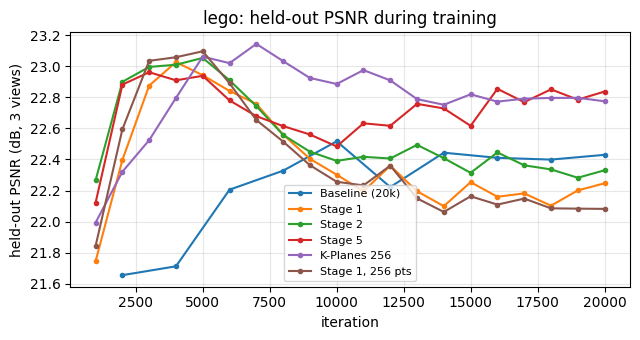

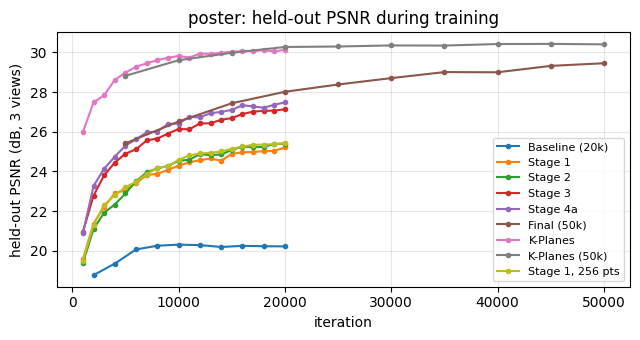

poster/train: 197 views, 270x480, fov=50.42 deg
poster/test: 29 views, 270x480, fov=50.42 deg


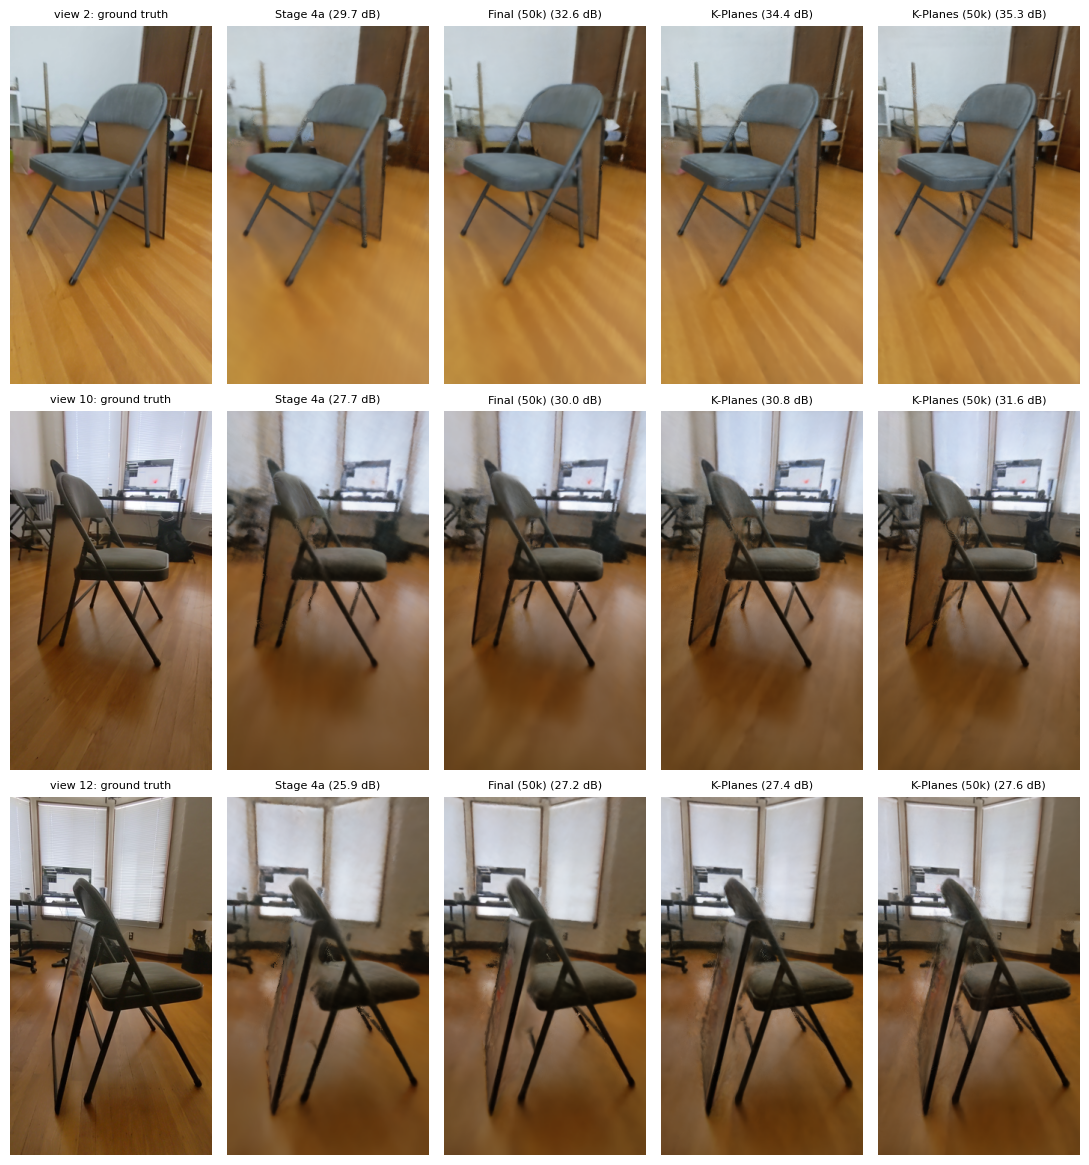

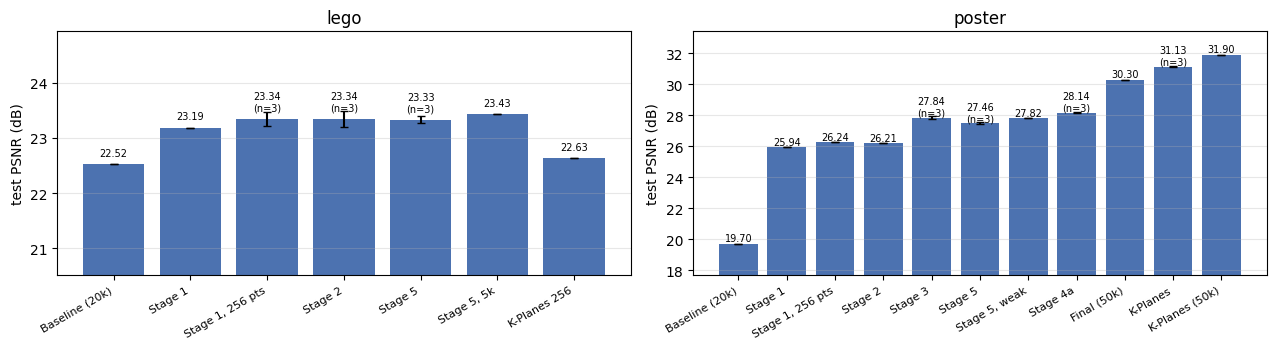

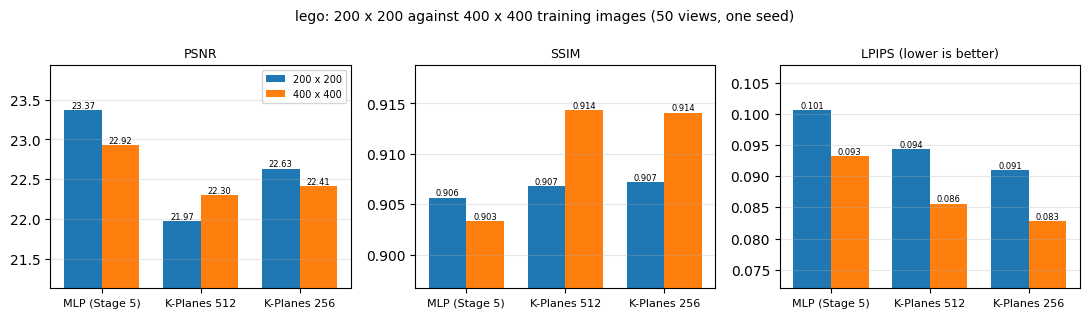

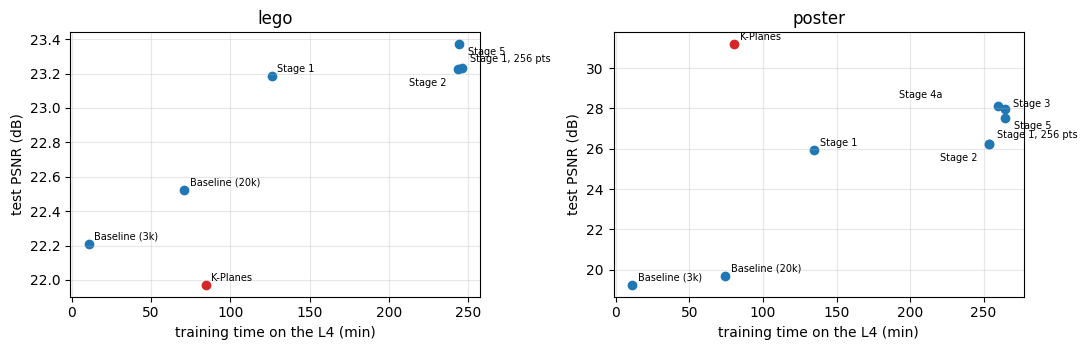

| Dataset | Run | PSNR (dB) | SSIM | LPIPS | Iterations | Train (min) | GPU |
| --- | --- | --- | --- | --- | --- | --- | --- |
| lego | A2 baseline (reported) | 22.16 | 0.841 | 0.169 | 3000 | 23.0 | Tesla T4 |
| lego | baseline_long | 22.52 | 0.899 | 0.094 | 20000 | 71.0 | NVIDIA L4 |
| lego | baseline_rerun | 22.21 | 0.841 | 0.169 | 3000 | 10.7 | NVIDIA L4 |
| lego | kplanes | 21.97 | 0.907 | 0.094 | 20000 | 84.5 | NVIDIA L4 |
| lego | kplanes_128 | 22.21 | 0.904 | 0.096 | 20000 | 24.3 | NVIDIA A100-SXM4-80GB |
| lego | kplanes_256 | 22.63 | 0.907 | 0.091 | 20000 | 23.9 | NVIDIA A100-SXM4-80GB |
| lego | kplanes_256_tv | 22.61 | 0.909 | 0.093 | 20000 | 23.6 | NVIDIA A100-SXM4-80GB |
| lego | kplanes_fullcoarse | 22.17 | 0.906 | 0.095 | 20000 | 37.6 | NVIDIA A100-SXM4-40GB |
| lego | stage1 | 23.19 | 0.896 | 0.118 | 20000 | 126.2 | NVIDIA L4 |
| lego | stage1_256pts | 23.23 | 0.903 | 0.105 | 20000 | 245.8 | NVIDIA L4 |
| lego | stage1_256pts_s2 | 23.49 | 0.903 | 0.102 | 20000 | 245.1 

In [15]:
FIG_DATASET = DATASET
if not MAKE_FIGURES:
    raise SystemExit('MAKE_FIGURES is False in section 10, so no figures are made in this notebook.')
ONLY_NEW = True   # True: only the figures made in the last session. False remakes every figure (about 30 min)
FIG_RUNS['poster'] = FIG_RUNS['poster'] + ['kplanes_long']
if not ONLY_NEW:
    for ds in ['lego', 'poster']:
        stage_comparison(ds)
    stage_comparison('lego', ['stage5', 'kplanes', 'kplanes_256', 'kplanes_128'], name='kplanes_comparison')
    kplanes_resolution()
    depth_comparison('lego', ['stage2', 'stage5', 'kplanes', 'kplanes_256'], view=18)
    depth_comparison('poster', ['stage2', 'stage3', 'final', 'kplanes'], view=10)
    make_video('lego', 'stage5')
    make_video('poster', 'kplanes')
for ds in ['lego', 'poster']:
    curve_comparison(ds)
stage_comparison('poster', ['stage4', 'final', 'kplanes', 'kplanes_long'], name='kplanes_comparison')
stage_bars({'lego': ['baseline_long', 'stage1', 'stage1_256pts', 'stage2', 'stage5', 'stage5_short', 'kplanes_256'],
            'poster': ['baseline_long', 'stage1', 'stage1_256pts', 'stage2', 'stage3', 'stage5', 'stage5_weak',
                       'stage4', 'final', 'kplanes', 'kplanes_long']})
resolution_test()
quality_vs_time()
results_table()
print('Figures saved to', FIG_DIR)